In [1]:
#Assignment 4    Implement Local Binary Pattern        
#    https://www.kaggle.com/code/phuc16102001/lbp-local-binary-pattern        
#    https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_local_binary_pattern.html        
#    https://www.geeksforgeeks.org/create-local-binary-pattern-of-an-image-using-opencv-python/

import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.feature import local_binary_pattern

img = data.camera()          # built-in grayscale image
print("Image shape:", img.shape)

Image shape: (512, 512)


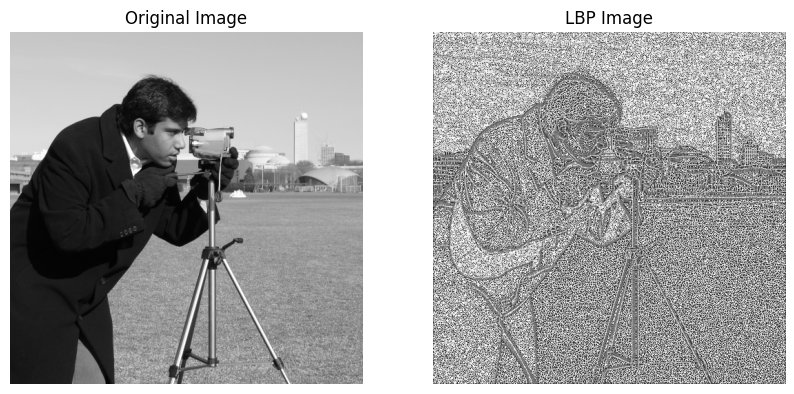

In [2]:
P, R = 8, 1                  # 8 neighbours, radius 1
lbp = local_binary_pattern(img, P, R, method='uniform')

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(lbp, cmap='gray')
plt.title('LBP Image')
plt.axis('off')
plt.show()

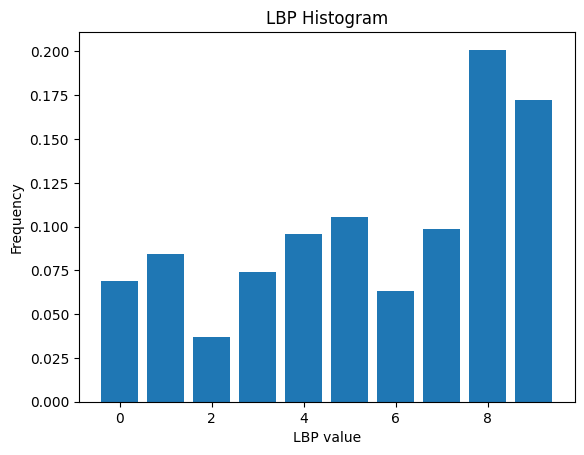

Number of bins: 10


In [3]:
n_bins = int(lbp.max() + 1)
hist, _ = np.histogram(lbp, bins=n_bins, range=(0, n_bins), density=True)

plt.bar(range(n_bins), hist)
plt.xlabel('LBP value')
plt.ylabel('Frequency')
plt.title('LBP Histogram')
plt.show()

print("Number of bins:", n_bins)

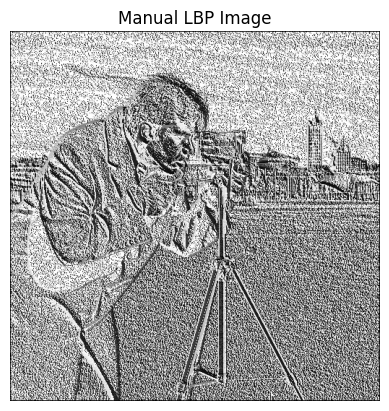

In [6]:
#  NOT REQUIRED
def manual_lbp(image):
    out = np.zeros_like(image)
    for x in range(1, image.shape[0] - 1):
        for y in range(1, image.shape[1] - 1):
            center = image[x, y]
            # 8 neighbours, clockwise from top-left
            neighbours = [image[x-1, y-1], image[x-1, y], image[x-1, y+1],
                          image[x, y+1], image[x+1, y+1], image[x+1, y],
                          image[x+1, y-1], image[x, y-1]]
            # 1 if neighbour >= centre else 0, then convert binary to decimal
            bits = [1 if n >= center else 0 for n in neighbours]
            out[x, y] = sum(b << i for i, b in enumerate(bits))
    return out

lbp_manual = manual_lbp(img)

plt.imshow(lbp_manual, cmap='gray')
plt.title('Manual LBP Image')
plt.axis('off')
plt.show()

In [ ]:
'''The LBP image highlights edges, corners and fine texture of the original image, while flat regions look uniform.
LBP converts raw pixel intensities into local texture codes, so the output is not an intensity picture but a texture map.
The histogram shows the distribution of texture patterns. Some bins (such as flat areas and edges) have higher frequency than others.
With the uniform method, the 256 possible patterns reduce to just 10 bins, giving a compact and efficient feature vector.
LBP is robust to lighting changes, since it depends on relative pixel differences and not absolute values.'''